# 07road: rail against road today (2025 and 2026)

**What it does:** compares the fastest scheduled train with driving by car between the 32 cities, for the 2025 and 2026 timetables. Where does the train win, where does the car win, and what did the 2026 speed restrictions change?

- **Train:** the full timetable answer from `02times` (fastest journey on a normal weekday, station to station, changes allowed, Renfe only): `times_2025.csv` (Wed 14 Jan 2026, feed of 18 Dec 2025) and `times_2026.csv` (Wed 25 Nov 2026).
- **Car:** driving times from OSRM (car profile) on the FOSSGIS server, OpenStreetMap data, one request for the whole 32 x 32 table. Same points as the train: each city's main station (Madrid = Atocha). Free flow: no traffic, no parking, no breaks. The raw answer is saved once and reused (set `FETCH_AGAIN = True` to fetch again).
- **Check:** OSRM against published driving times from RACE (Real Automovil Club de Espana) route pages for 8 city pairs.
- **Rules:** Madrid view uses the train time from Madrid (as on the map); for all 496 city pairs the faster direction is used for both modes (as for the key links). Measure = car time / train time (above 1: the train is faster).
- **Sensitivities (stated, not the main result):** (1) train + 30 min (getting to the station, AVE luggage check) against car + a 20 min break for every full 2 h of driving; (2) car times scaled to match RACE (OSRM came out a little slower than RACE, which favours the train).
- **Replacement bus:** in 2026 the Cordoba to Jaen line is closed for works and Renfe runs a bus ("Regional 13001" in the feed). Journeys using it are flagged (`bus_2026`), not removed (agreed 19 Nov).

**Inputs:** `data/clean/cities.csv`, `data/clean/times_<era>.csv`, `data/clean/journeys_<era>.csv`, `data/raw/manual/access_2025.csv`.
**Outputs:** `data/raw/osrm/osrm_car_table.json` (raw OSRM answer), `data/clean/road_times.csv`, `data/clean/rail_road_pairs.csv`, `data/clean/rail_road_madrid.csv`, `figures/07railroad.png`, `docs/data/railroad.json` (for the page).

**Data credit:** road network (c) OpenStreetMap contributors, ODbL; routing by OSRM on the FOSSGIS server (routing.openstreetmap.de). Train times from Renfe open GTFS. Reference driving times from RACE route pages (race.es), read 20 Nov 2026.

## 0. Settings

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import json
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt

CITIES_CSV = Path("data") / "clean" / "cities.csv"
ACCESS_CSV = Path("data") / "raw" / "manual" / "access_2025.csv"
CLEAN_DIR = Path("data") / "clean"
RAW_DIR = Path("data") / "raw" / "osrm"
RAW_FILE = RAW_DIR / "osrm_car_table.json"
FIG_DIR = Path("figures")
OSRM_URLS = ["https://routing.openstreetmap.de/routed-car/table/v1/driving/", "https://router.project-osrm.org/table/v1/driving/"]  # <- tried in order
FETCH_AGAIN = False  # <- True = ask OSRM again even if the raw file exists
SNAP_WARN_M = 250  # <- warn if OSRM moves a station point more than this to reach a road
ERAS = ["2025", "2026"]  # <- timetable eras compared with today's roads
CENTRE = "Madrid"  # <- the Madrid view
TRAIN_EXTRA_MIN = 30  # <- sensitivity: minutes added to every train trip (station access, luggage check)
BREAK_EVERY_MIN = 120  # <- sensitivity: one break for every full this many minutes of driving
BREAK_MIN = 20  # <- sensitivity: length of each break
CLOSE_BAND = 0.10  # <- "close" when car / train is within this share of 1
BUS_LEG = {"2026": ("Córdoba", "Jaén")}  # <- era: Renfe replacement bus between these two cities (line closed for works); journeys using it are flagged
COLOURS = {"full": "#1d6fa5", "part": "#b8860b", "none": "#c2410c"}  # <- VISUAL: access groups (validated set, from 04timemap)
CAR_COLOUR = "#6b6b6b"  # <- VISUAL: car marks
TEXT_COLOUR = "#333333"  # <- VISUAL: text

# Published driving times (fastest route on each RACE page), read 20 Nov 2026
RACE = "https://www.race.es/mapa-de-carreteras-espana/"
REFERENCE = [
    ("Madrid", "Barcelona", 390, 627, RACE + "ir-de-madrid-barcelona-en-coche"),
    ("Madrid", "Sevilla", 315, 530, RACE + "ir-de-madrid-sevilla-en-coche"),
    ("Valencia", "Madrid", 238, 360, RACE + "ir-de-valencia-madrid-en-coche"),
    ("Madrid", "Bilbao", 257, 402, RACE + "ir-de-madrid-bilbao-en-coche"),
    ("Madrid", "Málaga", 323, 536, RACE + "ir-de-madrid-malaga-en-coche"),
    ("A Coruña", "Madrid", 355, 592, RACE + "ir-de-a-coruna-madrid-en-coche"),
    ("Valencia", "Barcelona", 225, 348, RACE + "ir-de-valencia-barcelona-en-coche"),
    ("Sevilla", "Málaga", 141, 211, RACE + "ir-de-sevilla-malaga-en-coche"),
]  # <- (origin, destination, minutes, km, source)

FIG_DIR.mkdir(exist_ok=True)
RAW_DIR.mkdir(parents=True, exist_ok=True)

## 1. Cities and stations

In [2]:
cities = pd.read_csv(CITIES_CSV)
names = list(cities["city"])
access = pd.read_csv(ACCESS_CSV)
group = dict(zip(access["city"], access["access"]))
group[CENTRE] = "hub"
missing = [c for c in names if c not in group]
print(f"{len(names)} cities; access group missing for: {missing if missing else 'none'}")
coords = ";".join(f"{lon:.6f},{lat:.6f}" for lon, lat in zip(cities["lon"], cities["lat"]))

32 cities; access group missing for: none


## 2. Driving times from OSRM

One request for the whole table. The answer is saved with the server address and the time of the request, and reused afterwards.

In [3]:
def fetch_table():
    for base in OSRM_URLS:
        url = base + coords + "?annotations=duration,distance"
        try:
            reply = requests.get(url, timeout=120)
        except requests.RequestException as error:
            print(f"{base}: no answer ({error})")
            continue
        if reply.status_code != 200:
            print(f"{base}: HTTP {reply.status_code}")
            continue
        answer = reply.json()
        if answer.get("code") != "Ok":
            print(f"{base}: OSRM code {answer.get('code')}")
            continue
        answer["fetched_utc"] = datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M")
        answer["server"] = base
        answer["cities"] = names
        return answer
    raise RuntimeError("No OSRM server answered: check the internet connection or try again later.")


if RAW_FILE.exists() and not FETCH_AGAIN:
    osrm = json.loads(RAW_FILE.read_text(encoding="utf-8"))
    print(f"reused {RAW_FILE}")
else:
    osrm = fetch_table()
    RAW_FILE.write_text(json.dumps(osrm), encoding="utf-8")
    print(f"fetched and saved {RAW_FILE}")
print(f"server: {osrm.get('server', '?')}, fetched (UTC): {osrm.get('fetched_utc', '?')}")
if osrm.get("cities", names) != names:
    raise ValueError("The saved OSRM answer has a different city list: set FETCH_AGAIN = True.")

snap = pd.Series([p["distance"] for p in osrm["sources"]], index=names)
print(f"station points moved to the nearest road: median {snap.median():.0f} m, max {snap.max():.0f} m ({snap.idxmax()})")
far = snap[snap > SNAP_WARN_M]
print(f"moved more than {SNAP_WARN_M} m: {list(far.index) if len(far) else 'none'}")

road_min = pd.DataFrame(np.array(osrm["durations"], dtype=float) / 60, index=names, columns=names)
road_km = pd.DataFrame(np.array(osrm["distances"], dtype=float) / 1000, index=names, columns=names)
print(f"missing routes: {int(road_min.isna().sum().sum())}")

reused data\raw\osrm\osrm_car_table.json
server: https://routing.openstreetmap.de/routed-car/table/v1/driving/, fetched (UTC): 2026-11-20 01:57
station points moved to the nearest road: median 26 m, max 86 m (Zaragoza)
moved more than 250 m: none
missing routes: 0


## 3. Road table and basic checks

In [4]:
off = ~np.eye(len(names), dtype=bool)
gap = np.abs(road_min.values - road_min.values.T)[off]
print(f"difference between the two directions: median {np.median(gap):.1f} min, max {gap.max():.1f} min")
speed = road_km.values[off] / (road_min.values[off] / 60)
print(f"average driving speed: median {np.median(speed):.0f} km/h (range {speed.min():.0f} to {speed.max():.0f})")

road_long = road_min.stack().rename("road_min").to_frame()
road_long["road_km"] = road_km.stack()
road_long.index.names = ["origin", "destination"]
road_long = road_long.reset_index()
road_long = road_long[road_long["origin"] != road_long["destination"]]
road_long["road_min"] = road_long["road_min"].round(1)
road_long["road_km"] = road_long["road_km"].round(1)
road_long.to_csv(CLEAN_DIR / "road_times.csv", index=False)
print(f"saved road_times.csv ({len(road_long)} directed pairs)")

difference between the two directions: median 1.7 min, max 9.3 min
average driving speed: median 90 km/h (range 67 to 98)
saved road_times.csv (992 directed pairs)


## 4. Check against published driving times (RACE)

RACE gives the time for its fastest route between city centres; OSRM is station to station, so a few km and minutes of difference are expected.

In [5]:
ref = pd.DataFrame(REFERENCE, columns=["origin", "destination", "race_min", "race_km", "source"])
ref["osrm_min"] = [road_min.loc[o, d] for o, d in zip(ref["origin"], ref["destination"])]
ref["osrm_km"] = [road_km.loc[o, d] for o, d in zip(ref["origin"], ref["destination"])]
ref["diff_min"] = ref["osrm_min"] - ref["race_min"]
ref["ratio"] = ref["osrm_min"] / ref["race_min"]
ref["km_ratio"] = ref["osrm_km"] / ref["race_km"]
print(ref[["origin", "destination", "race_min", "osrm_min", "diff_min", "ratio", "race_km", "osrm_km", "km_ratio"]].round(2).to_string(index=False))
ROAD_SCALE = float(ref["ratio"].median())
print(f"OSRM / RACE time: median {ROAD_SCALE:.3f} (range {ref['ratio'].min():.3f} to {ref['ratio'].max():.3f}); distance: median {ref['km_ratio'].median():.3f}")
print(f"second sensitivity: car times divided by {ROAD_SCALE:.3f} to match RACE")

  origin destination  race_min  osrm_min  diff_min  ratio  race_km  osrm_km  km_ratio
  Madrid   Barcelona       390    405.40     15.40   1.04      627   615.55      0.98
  Madrid     Sevilla       315    347.70     32.70   1.10      530   532.12      1.00
Valencia      Madrid       238    233.67     -4.33   0.98      360   353.87      0.98
  Madrid      Bilbao       257    267.10     10.10   1.04      402   396.92      0.99
  Madrid      Málaga       323    359.70     36.70   1.11      536   531.81      0.99
A Coruña      Madrid       355    389.27     34.27   1.10      592   593.38      1.00
Valencia   Barcelona       225    235.71     10.71   1.05      348   349.27      1.00
 Sevilla      Málaga       141    149.48      8.48   1.06      211   209.30      0.99
OSRM / RACE time: median 1.054 (range 0.982 to 1.114); distance: median 0.992
second sensitivity: car times divided by 1.054 to match RACE


## 5. Train against car for every city pair

Both modes use the faster direction of each pair. `changes` = changes on the fastest train journey in that direction.

In [6]:
rail = {}
journeys = {}
for era in ERAS:
    rail[era] = pd.read_csv(CLEAN_DIR / f"times_{era}.csv", index_col=0).loc[names, names]
    journeys[era] = pd.read_csv(CLEAN_DIR / f"journeys_{era}.csv").set_index(["origin", "destination"])

def uses_bus(era, o, d):
    if era not in BUS_LEG:
        return False
    x, y = BUS_LEG[era]
    if {o, d} == {x, y}:
        return True
    change = str(journeys[era].loc[(o, d), "change_at"])
    end = y if o == y or d == y else (x if o == x or d == x else None)
    other = x if end == y else y
    return end is not None and change.startswith(other[:5])


rows = []
for i, a in enumerate(names):
    for b in names[i + 1:]:
        row = {"city_a": a, "city_b": b}
        forward = road_min.loc[a, b] <= road_min.loc[b, a]
        row["road_min"] = min(road_min.loc[a, b], road_min.loc[b, a])
        row["road_km"] = road_km.loc[a, b] if forward else road_km.loc[b, a]
        for era in ERAS:
            ab = rail[era].loc[a, b]
            ba = rail[era].loc[b, a]
            o, d = (a, b) if ab <= ba else (b, a)
            row[f"rail_{era}"] = min(ab, ba)
            row[f"changes_{era}"] = int(journeys[era].loc[(o, d), "changes"])
            row[f"bus_{era}"] = uses_bus(era, o, d)
        rows.append(row)
pairs = pd.DataFrame(rows)
for era in ERAS:
    pairs[f"ratio_{era}"] = pairs["road_min"] / pairs[f"rail_{era}"]
    pairs[f"train_wins_{era}"] = pairs[f"ratio_{era}"] > 1
    breaks = np.floor(pairs["road_min"] / BREAK_EVERY_MIN) * BREAK_MIN
    pairs[f"ratio_sens_{era}"] = (pairs["road_min"] + breaks) / (pairs[f"rail_{era}"] + TRAIN_EXTRA_MIN)
    pairs[f"ratio_race_{era}"] = (pairs["road_min"] / ROAD_SCALE) / pairs[f"rail_{era}"]
print(f"{len(pairs)} city pairs; missing train times: {int(pairs[[f'rail_{e}' for e in ERAS]].isna().sum().sum())}")

for era in ERAS:
    wins = pairs[f"train_wins_{era}"]
    close = (pairs[f"ratio_{era}"] - 1).abs() <= CLOSE_BAND
    sens = pairs[f"ratio_sens_{era}"] > 1
    race = pairs[f"ratio_race_{era}"] > 1
    print(f"{era}: train faster for {wins.sum()} of {len(pairs)} pairs ({wins.mean():.0%}); within {CLOSE_BAND:.0%} of the car: {close.sum()}; median car / train {pairs[f'ratio_{era}'].median():.2f}")
    print(f"      sensitivities: train faster for {sens.sum()} (train + {TRAIN_EXTRA_MIN} min, car + breaks), {race.sum()} (car scaled to RACE)")
for era in BUS_LEG:
    flagged = pairs[pairs[f"bus_{era}"]]
    print(f"{era}: {len(flagged)} pairs use the replacement bus {BUS_LEG[era][0]} to {BUS_LEG[era][1]}; train faster for {flagged[f'train_wins_{era}'].sum()} of them")

496 city pairs; missing train times: 0
2025: train faster for 315 of 496 pairs (64%); within 10% of the car: 88; median car / train 1.17
      sensitivities: train faster for 334 (train + 30 min, car + breaks), 289 (car scaled to RACE)
2026: train faster for 309 of 496 pairs (62%); within 10% of the car: 84; median car / train 1.14
      sensitivities: train faster for 324 (train + 30 min, car + breaks), 287 (car scaled to RACE)
2026: 13 pairs use the replacement bus Córdoba to Jaén; train faster for 4 of them


### 5a. Direct trains against trips with a change

In [7]:
for era in ERAS:
    direct = pairs[f"changes_{era}"] == 0
    for label, part in [("direct train", pairs[direct]), ("with a change", pairs[~direct])]:
        print(f"{era}, {label}: {len(part)} pairs, train faster for {part[f'train_wins_{era}'].sum()} ({part[f'train_wins_{era}'].mean():.0%}), median car / train {part[f'ratio_{era}'].median():.2f}")

2025, direct train: 131 pairs, train faster for 102 (78%), median car / train 1.66
2025, with a change: 365 pairs, train faster for 213 (58%), median car / train 1.09
2026, direct train: 126 pairs, train faster for 99 (79%), median car / train 1.63
2026, with a change: 370 pairs, train faster for 210 (57%), median car / train 1.07


### 5b. By driving time

In [8]:
bands = pd.cut(pairs["road_min"], bins=[0, 120, 240, 360, 10000], labels=["under 2 h", "2 to 4 h", "4 to 6 h", "over 6 h"])
for era in ERAS:
    table = pairs.groupby(bands, observed=True).agg(pairs_n=(f"ratio_{era}", "size"), train_wins=(f"train_wins_{era}", "sum"), median_ratio=(f"ratio_{era}", "median"))
    print(f"--- {era}")
    print(table.round(2).to_string())

--- 2025
           pairs_n  train_wins  median_ratio
road_min                                    
under 2 h       30          18          1.19
2 to 4 h        78          31          0.85
4 to 6 h        94          47          0.99
over 6 h       294         219          1.26
--- 2026
           pairs_n  train_wins  median_ratio
road_min                                    
under 2 h       30          17          1.18
2 to 4 h        78          30          0.84
4 to 6 h        94          47          0.99
over 6 h       294         215          1.24


### 5c. Pairs that changed sides between 2025 and 2026

In [9]:
lost = pairs[pairs["train_wins_2025"] & ~pairs["train_wins_2026"]]
gained = pairs[~pairs["train_wins_2025"] & pairs["train_wins_2026"]]
show = ["city_a", "city_b", "road_min", "rail_2025", "rail_2026", "ratio_2025", "ratio_2026"]
print(f"train faster in 2025 but not in 2026: {len(lost)}")
print(lost[show].round(2).to_string(index=False) if len(lost) else "none")
print(f"train faster in 2026 but not in 2025: {len(gained)}")
print(gained[show].round(2).to_string(index=False) if len(gained) else "none")

train faster in 2025 but not in 2026: 9
   city_a        city_b  road_min  rail_2025  rail_2026  ratio_2025  ratio_2026
  Sevilla         Cádiz     87.82       84.0       97.0        1.05        0.91
  Sevilla          Jaén    177.72      177.0      178.0        1.00        1.00
   Málaga        Huelva    216.42      195.0      237.0        1.11        0.91
Barcelona     Santander    457.23      456.0      467.0        1.00        0.98
   Girona     Santander    507.22      507.0      573.0        1.00        0.89
 Albacete        Huelva    400.60      391.0      404.0        1.02        0.99
 Alicante San Sebastián    494.60      490.0      498.0        1.01        0.99
   Oviedo          Jaén    509.96      499.0      519.0        1.02        0.98
   Oviedo        Huelva    557.60      550.0      593.0        1.01        0.94
train faster in 2026 but not in 2025: 3
    city_a        city_b  road_min  rail_2025  rail_2026  ratio_2025  ratio_2026
     Cádiz San Sebastián    673.66     

## 6. The Madrid view

Train time from Madrid (as on the map), car time from Madrid.

In [10]:
others = [c for c in names if c != CENTRE]
mad = pd.DataFrame({"city": others})
mad["access"] = [group[c] for c in others]
mad["road_min"] = [road_min.loc[CENTRE, c] for c in others]
mad["road_km"] = [road_km.loc[CENTRE, c] for c in others]
for era in ERAS:
    mad[f"rail_{era}"] = [rail[era].loc[CENTRE, c] for c in others]
    mad[f"changes_{era}"] = [int(journeys[era].loc[(CENTRE, c), "changes"]) for c in others]
    mad[f"bus_{era}"] = [uses_bus(era, CENTRE, c) for c in others]
    mad[f"ratio_{era}"] = mad["road_min"] / mad[f"rail_{era}"]
    breaks = np.floor(mad["road_min"] / BREAK_EVERY_MIN) * BREAK_MIN
    mad[f"ratio_sens_{era}"] = (mad["road_min"] + breaks) / (mad[f"rail_{era}"] + TRAIN_EXTRA_MIN)
    mad[f"ratio_race_{era}"] = (mad["road_min"] / ROAD_SCALE) / mad[f"rail_{era}"]
mad = mad.sort_values("ratio_2025", ascending=False).reset_index(drop=True)
print(mad[["city", "access", "road_min", "rail_2025", "rail_2026", "ratio_2025", "ratio_2026", "ratio_sens_2025", "ratio_race_2025", "bus_2026"]].round(2).to_string(index=False))

for era in ERAS:
    wins = mad[f"ratio_{era}"] > 1
    print(f"{era}: train faster from Madrid to {wins.sum()} of {len(mad)} cities; car faster to: {list(mad.loc[~wins, 'city'])}")
    print(f"      sensitivities: train faster to {(mad[f'ratio_sens_{era}'] > 1).sum()} (train + {TRAIN_EXTRA_MIN} min, car + breaks), {(mad[f'ratio_race_{era}'] > 1).sum()} (car scaled to RACE)")
print("median car / train by access group (2025, 2026):")
print(mad.groupby("access")[["ratio_2025", "ratio_2026"]].median().round(2).to_string())

mad_out = mad.copy()
pairs_out = pairs.copy()
for frame in (mad_out, pairs_out):
    for column in frame.columns:
        if frame[column].dtype == float:
            frame[column] = frame[column].round(3)
mad_out.to_csv(CLEAN_DIR / "rail_road_madrid.csv", index=False)
pairs_out.to_csv(CLEAN_DIR / "rail_road_pairs.csv", index=False)
print("saved rail_road_madrid.csv and rail_road_pairs.csv")

         city access  road_min  rail_2025  rail_2026  ratio_2025  ratio_2026  ratio_sens_2025  ratio_race_2025  bus_2026
    Tarragona   full    357.53      124.0      147.0        2.88        2.43             2.58             2.74     False
  Ciudad Real   full    149.01       54.0       53.0        2.76        2.81             2.01             2.62     False
   Valladolid   full    148.33       54.0       54.0        2.75        2.75             2.00             2.61     False
     Zaragoza   full    212.20       78.0       95.0        2.72        2.23             2.15             2.58     False
    Barcelona   full    405.40      157.0      182.0        2.58        2.23             2.49             2.45     False
      Córdoba   full    266.77      104.0      104.0        2.57        2.57             2.29             2.43     False
       Lleida   full    306.27      122.0      143.0        2.51        2.14             2.28             2.38     False
      Ourense   full    336.23  

## 7. Draft figure

Left: from Madrid, car (grey bar end) against train 2025 (filled dot) and 2026 (open dot). Right: all 496 pairs, train against car, 2025 (blue: direct train, grey: with a change).

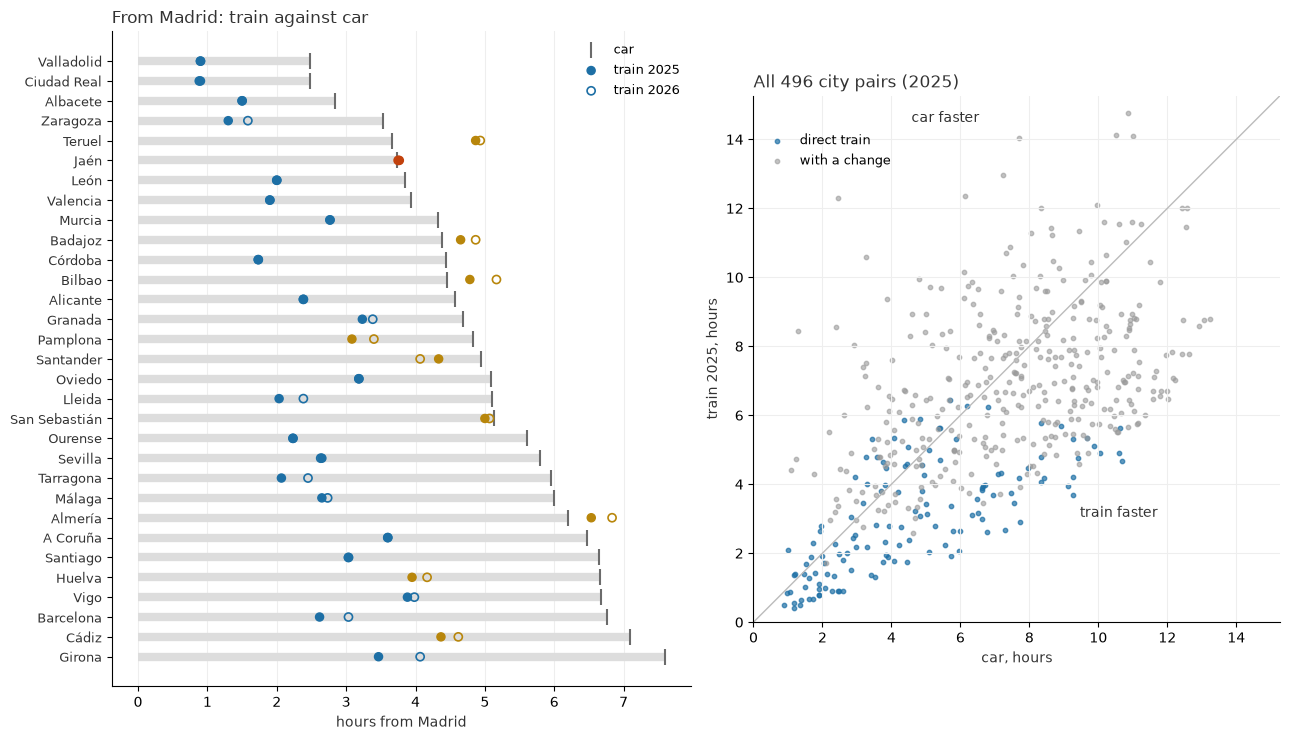

In [11]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 7.5), gridspec_kw={"width_ratios": [1.1, 1]})
order = mad.sort_values("road_min").reset_index(drop=True)
y = np.arange(len(order))
ax1.hlines(y, 0, order["road_min"] / 60, color="#dddddd", linewidth=6)
ax1.scatter(order["road_min"] / 60, y, marker="|", s=120, color=CAR_COLOUR, label="car", zorder=3)
dot_colours = [COLOURS[a] for a in order["access"]]
ax1.scatter(order["rail_2025"] / 60, y, s=34, color=dot_colours, zorder=4, label="train 2025")
ax1.scatter(order["rail_2026"] / 60, y, s=34, facecolors="none", edgecolors=dot_colours, linewidths=1.2, zorder=4, label="train 2026")
ax1.set_yticks(y)
ax1.set_yticklabels(order["city"], fontsize=9, color=TEXT_COLOUR)
ax1.invert_yaxis()
ax1.set_xlabel("hours from Madrid", color=TEXT_COLOUR)
ax1.set_title("From Madrid: train against car", loc="left", color=TEXT_COLOUR, fontsize=12)
ax1.grid(axis="x", color="#eeeeee")
ax1.legend(loc="upper right", frameon=False, fontsize=9)

top = max(pairs["road_min"].max(), pairs["rail_2025"].max()) / 60 + 0.5
direct = pairs["changes_2025"] == 0
ax2.plot([0, top], [0, top], color="#bbbbbb", linewidth=1)
ax2.scatter(pairs.loc[direct, "road_min"] / 60, pairs.loc[direct, "rail_2025"] / 60, s=10, color=COLOURS["full"], alpha=0.7, label="direct train")
ax2.scatter(pairs.loc[~direct, "road_min"] / 60, pairs.loc[~direct, "rail_2025"] / 60, s=10, color="#9a9a9a", alpha=0.6, label="with a change")
ax2.text(top * 0.62, top * 0.2, "train faster", color=TEXT_COLOUR, fontsize=10)
ax2.text(top * 0.3, top * 0.95, "car faster", color=TEXT_COLOUR, fontsize=10)
ax2.set_xlim(0, top)
ax2.set_ylim(0, top)
ax2.set_aspect("equal")
ax2.set_xlabel("car, hours", color=TEXT_COLOUR)
ax2.set_ylabel("train 2025, hours", color=TEXT_COLOUR)
ax2.set_title("All 496 city pairs (2025)", loc="left", color=TEXT_COLOUR, fontsize=12)
ax2.grid(color="#eeeeee")
ax2.legend(loc="upper left", frameon=False, fontsize=9, bbox_to_anchor=(0, 0.95))
for ax in (ax1, ax2):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR / "07railroad.png", dpi=150)
plt.show()

## 8. Page data (part 3)

A small JSON file for the time map page (`docs/index.html`): driving times, the full timetable times and changes for each era, and the trips that use the replacement bus. City order = `cities.csv`; the page matches cities by name.

In [12]:
PAGE_FILE = Path("docs") / "data" / "railroad.json"
bus = {}
for era in BUS_LEG:
    bus[era] = [[o, d] for o in names for d in names if o != d and uses_bus(era, o, d)]
page = {
    "cities": names,
    "eras": ERAS,
    "road_min": [[round(float(road_min.loc[o, d]), 1) for d in names] for o in names],
    "rail_min": {era: [[float(rail[era].loc[o, d]) if o != d else 0.0 for d in names] for o in names] for era in ERAS},
    "changes": {era: [[int(journeys[era].loc[(o, d), "changes"]) if o != d else 0 for d in names] for o in names] for era in ERAS},
    "bus": bus,
    "bus_note": "includes the Renfe replacement bus between Cordoba and Jaen (line closed for works)",
    "close_band": CLOSE_BAND,
    "road_scale_vs_race": round(ROAD_SCALE, 3),
    "credits": "Driving times: OSRM (FOSSGIS server) on OpenStreetMap data, (c) OpenStreetMap contributors, ODbL; free flow, no traffic or breaks; fetched " + str(osrm.get("fetched_utc", "")) + " UTC.",
}
PAGE_FILE.parent.mkdir(parents=True, exist_ok=True)
text = json.dumps(page, ensure_ascii=False, allow_nan=False, separators=(",", ":"))
PAGE_FILE.write_text(text, encoding="utf-8")
print(f"saved {PAGE_FILE} ({len(text) / 1024:.0f} KB); bus trips flagged: {sum(len(v) for v in bus.values())}")
check = json.loads(PAGE_FILE.read_text(encoding="utf-8"))
print(f"check: Madrid to Barcelona by car {check['road_min'][0][names.index('Barcelona')]} min, train 2025 {check['rail_min']['2025'][0][names.index('Barcelona')]} min")

saved docs\data\railroad.json (23 KB); bus trips flagged: 24
check: Madrid to Barcelona by car 405.4 min, train 2025 157.0 min


___
**END**